### Introduction to Quantum Mechanics, Second Edition | David J. Griffiths | Solutions and Code by David A. Lee
### Chapter 1: The Wave Function

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

import sys; sys.path.insert(0, r"C:\Users\david\Documents\physics")
from plotstyle import THEME, C, FG, savefig

In [2]:
def style_ax(ax, xlabel='$x$', ylabel='$y$', xlim=None, ylim=None,
             xticks=None, xticklabels=None, yticks=None, yticklabels=None,
             color=FG, fontsize=16):
    """Apply shared plot attributes to one or more axes."""
    axes = np.atleast_1d(ax)
    for a in axes:
        a.set_xlabel(xlabel, color=color, fontsize=fontsize)
        a.set_ylabel(ylabel, color=color, fontsize=fontsize)
        a.tick_params(colors=color)
        a.tick_params(labelsize=fontsize)
        a.tick_params(which='minor', top=False, bottom=False, left=False, right=False)
        a.grid(False)
        if xlim is not None:
            a.set_xlim(xlim)
        if ylim is not None:
            a.set_ylim(ylim)
        if xticks is not None:
            a.set_xticks(xticks)
        if xticklabels is not None:
            a.set_xticklabels(xticklabels, color=color)
        if yticks is not None:
            a.set_yticks(yticks)
        if yticklabels is not None:
            a.set_yticklabels(yticklabels, color=color)

Question 1.3

(c)

saved chap1ex1.3c.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1


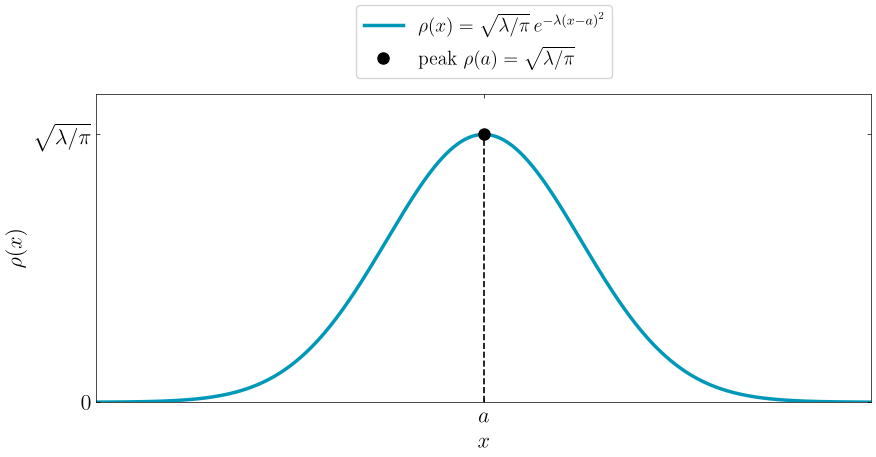

In [3]:
# rho(x) = A exp(-lambda (x - a)^2),  A = sqrt(lambda/pi),  sigma = 1/sqrt(2 lambda)
# Gaussian centered at a, peak A. Take a = 0, lambda = 1
# and label ticks symbolically so the sketch holds for any a, lambda.
a, lam = 0.0, 1.0
A = np.sqrt(lam/np.pi)
sigma = 1/np.sqrt(2*lam)

x = np.linspace(a - 4*sigma, a + 4*sigma, 801)
rho = A*np.exp(-lam*(x - a)**2)

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, rho, color=C.cyan, linewidth=2.5, label=r'$\rho(x) = \sqrt{\lambda/\pi}\, e^{-\lambda (x - a)^2}$')
ax.vlines(a, 0, A, colors=FG, linestyles='--', linewidths=1.2)
ax.plot(a, A, 'o', color=FG, markersize=8, zorder=3, label=r'peak $\rho(a) = \sqrt{\lambda/\pi}$')

style_ax(ax, xlabel='$x$', ylabel=r'$\rho(x)$', xlim=(a - 4*sigma, a + 4*sigma), ylim=(0, 1.15*A),
         xticks=[a], xticklabels=['$a$'],
         yticks=[0, A], yticklabels=['$0$', r'$\sqrt{\lambda/\pi}$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1)

savefig(fig, "chap1ex1.3c.pdf")
plt.show()


Question 1.4

(b)

saved chap1ex1.4b.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1


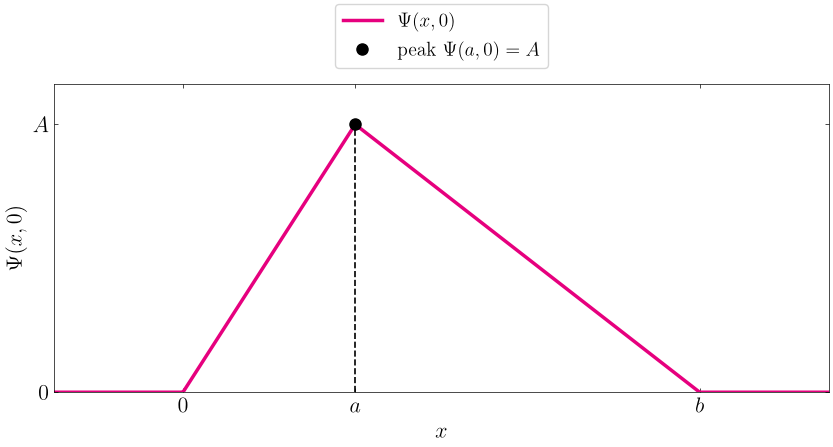

In [4]:
# Psi(x,0) = A x/a on [0,a],  A (b-x)/(b-a) on [a,b],  0 otherwise.  Peak A at x = a.
# Take a = 1, b = 3 and label ticks symbolically so the sketch holds for any 0 < a < b.
a, b, A = 1.0, 3.0, 1.0

x = np.linspace(-0.25*b, 1.25*b, 801)
psi = np.where((x >= 0) & (x <= a), A*x/a,
      np.where((x > a) & (x <= b), A*(b - x)/(b - a), 0.0))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, psi, color=C.magenta, linewidth=2.5, label=r'$\Psi(x, 0)$')
ax.vlines(a, 0, A, colors=FG, linestyles='--', linewidths=1.2)
ax.plot(a, A, 'o', color=FG, markersize=8, zorder=3, label=r'peak $\Psi(a, 0) = A$')

style_ax(ax, xlabel='$x$', ylabel=r'$\Psi(x, 0)$', xlim=(-0.25*b, 1.25*b), ylim=(0, 1.15*A),
         xticks=[0, a, b], xticklabels=['$0$', '$a$', '$b$'],
         yticks=[0, A], yticklabels=['$0$', '$A$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1)

savefig(fig, "chap1ex1.4b.pdf")
plt.show()


Question 1.5

(c)

saved chap1ex1.5c.pdf -> \\wsl.localhost\Ubuntu-22.04\home\cantorian_infinity\physics\introquantummechanics\chap1


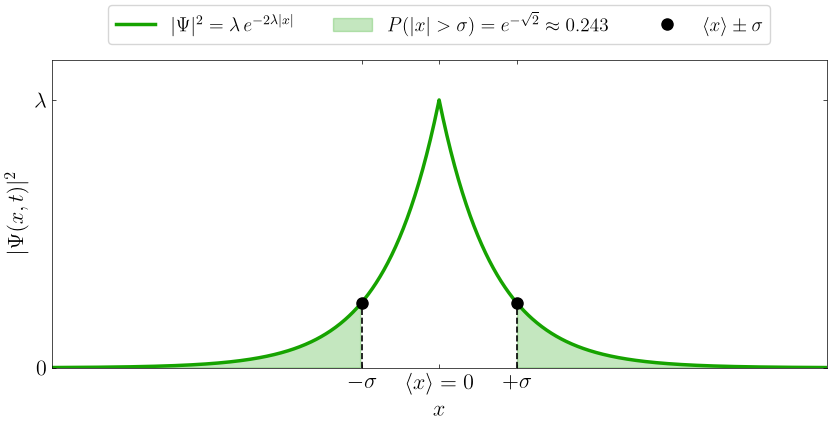

In [5]:
# |Psi|^2 = A^2 exp(-2 lambda |x|),  A = sqrt(lambda)  (normalization),  <x> = 0,  <x^2> = 1/(2 lambda^2),  sigma = 1/(sqrt(2) lambda).
# P(outside <x> +/- sigma) = exp(-2 lambda sigma) = exp(-sqrt(2)) ~ 0.243.
# Take lambda = 1 and label ticks symbolically so the sketch holds for any lambda > 0.
lam = 1.0
A2 = lam
sigma = 1/(np.sqrt(2)*lam)
p_out = np.exp(-np.sqrt(2))

x = np.linspace(-5*sigma, 5*sigma, 801)
rho = A2*np.exp(-2*lam*np.abs(x))

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(x, rho, color=C.green, linewidth=2.5, label=r'$|\Psi|^2 = \lambda\, e^{-2\lambda|x|}$')
ax.fill_between(x, rho, where=np.abs(x) > sigma, color=C.green, alpha=0.25,
                label=rf'$P(|x| > \sigma) = e^{{-\sqrt{{2}}}} \approx {p_out:.3f}$')
ax.vlines([-sigma, sigma], 0, A2*np.exp(-2*lam*sigma), colors=FG, linestyles='--', linewidths=1.2)
ax.plot([-sigma, sigma], [A2*np.exp(-2*lam*sigma)]*2, 'o', color=FG, markersize=8, zorder=3,
        label=r'$\langle x \rangle \pm \sigma$')

style_ax(ax, xlabel='$x$', ylabel=r'$|\Psi(x, t)|^2$', xlim=(-5*sigma, 5*sigma), ylim=(0, 1.15*A2),
         xticks=[-sigma, 0, sigma], xticklabels=[r'$-\sigma$', r'$\langle x \rangle = 0$', r'$+\sigma$'],
         yticks=[0, A2], yticklabels=['$0$', r'$\lambda$'])
ax.legend(frameon=True, fontsize=14, loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3)

savefig(fig, "chap1ex1.5c.pdf")
plt.show()
